# Métricas de la trivia — Robot Romeo
**Sesión 8 nov 2026 · captura con `ROMEO_MEDIR=1`**

Solo métricas de la **trivia**. Este notebook lee los CSV crudos y genera las gráficas.

**Nodos del sistema:** `communication_node` (STT+TTS) · `expression_faces_node` (FER+caras) · `moving_control_node` (carrito) · `orchestrator_node` (afectiva PULSE/ROSE/AEB + LLM + trivia).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": "DejaVu Sans",
})
GRIS="#2b3a52"; VERDE="#1ba378"; NARANJA="#e07a1a"; AZUL="#2a78d6"; ROJO="#c0392b"

BASE = Path(r".")   # misma carpeta del notebook
def ruta(n): return BASE / n

## 1. Cargar los datos

In [2]:
# La trivia empieza en la PRIMERA pregunta que hace Romeo (Asistente [emo]: ...?).
# Antes van el saludo y "quiero jugar", que NO son preguntas: se descartan.
import re
INICIO_TRIVIA = 0.0
try:
    log = open(ruta("romeo_run.log"), encoding="utf-8", errors="replace").read()
    # primero intenta "Vamos con una trivia"; si no, la primera pregunta
    m = re.search(r"\[(\d+\.\d+)\].*Vamos con una trivia", log)
    if not m:
        m = re.search(r"\[(\d+\.\d+)\].*Asistente \[[^\]]+\]: [^\n]*\?", log)
    if m: INICIO_TRIVIA = float(m.group(1))
except OSError: pass
print("La trivia empieza en t =", INICIO_TRIVIA)

La trivia empieza en t = 1794212271.0799959


In [3]:
# turnos (Pi): afectiva + LLM + tokens, SOLO desde que inicia la trivia
filas = []
with open(ruta("turnos.csv"), encoding="utf-8", errors="replace") as f:
    next(f)
    for ln in f:
        nums=[]
        for x in ln.split(","):
            try: nums.append(float(x))
            except ValueError: pass
        if len(nums) < 4: continue
        ei = next((i for i,v in enumerate(nums) if v > 1e9), None)
        if ei is None or ei < 3: continue
        t_fin = nums[ei]
        if t_fin < INICIO_TRIVIA: continue   # descarta saludo + pedir jugar
        t_llm=nums[ei-1]; tok=nums[ei-3]; afect=nums[0]*1000
        if 50 <= t_llm <= 5000 and 1 <= tok <= 200:
            filas.append({"t_llm_ms":t_llm,"tokens_salida":tok,
                          "afectiva_ms": afect if afect < 3000 else np.nan})
N_PREGUNTAS = 33   # la sesion de trivia: primeras 33 preguntas
turnos = pd.DataFrame(filas[:N_PREGUNTAS])
mod = pd.read_csv(ruta("modulos_pc.csv"))
tts = pd.read_csv(ruta("tts.csv"))
sis = pd.read_csv(ruta("sistema.csv"))
sis["min"] = (sis["t"] - sis["t"].iloc[0]) / 60
print("turnos:", len(turnos), "| modulos:", len(mod), "| tts:", len(tts), "| sistema:", len(sis))

turnos: 33 | modulos: 341 | tts: 70 | sistema: 544


## 2. Comparación Rocha vs IA  —  ¿coincide la respuesta?

Para cada pregunta de la trivia, la respuesta **generada por el LLM** se compara con la **respuesta por defecto de Rocha** (del banco de preguntas). Un LLM juez decide si coinciden. Por categoría.

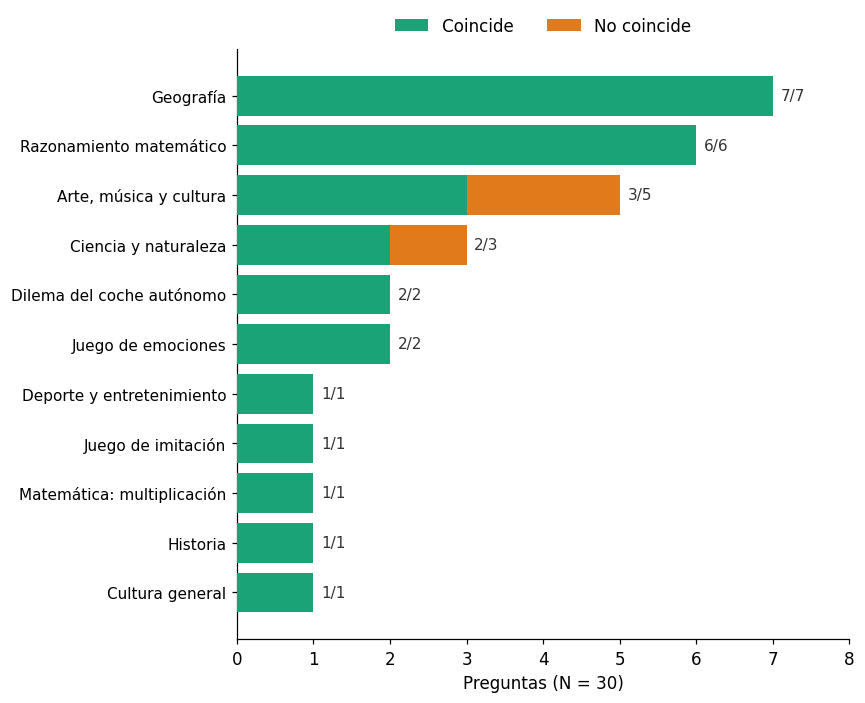

Coincidencia Rocha vs IA: 27/30 = 90%


In [4]:
# Datos de la comparacion Coincide / No coincide (27/30 = 90%).
# 'Reconocimiento musical' (0/2) es parte de 'Arte, musica y cultura' (3/3),
# asi que se fusionan: Arte, musica y cultura = 3/5.
cats = [
    ("Geografía",7,7),("Razonamiento matemático",6,6),("Arte, música y cultura",3,5),
    ("Ciencia y naturaleza",2,3),("Dilema del coche autónomo",2,2),("Juego de emociones",2,2),
    ("Deporte y entretenimiento",1,1),("Juego de imitación",1,1),
    ("Matemática: multiplicación",1,1),("Historia",1,1),("Cultura general",1,1),
]
dfc = pd.DataFrame(cats, columns=["categoria","coincide","total"])
dfc["no_coincide"] = dfc["total"] - dfc["coincide"]
dfc = dfc.iloc[::-1].reset_index(drop=True)  # orden como el ejemplo (mayor arriba)

fig, ax = plt.subplots(figsize=(8,6.5))
y = np.arange(len(dfc))
ax.barh(y, dfc["coincide"], color=VERDE, zorder=3, label="Coincide")
ax.barh(y, dfc["no_coincide"], left=dfc["coincide"], color=NARANJA, zorder=3, label="No coincide")
for i,(c,t) in enumerate(zip(dfc["coincide"], dfc["total"])):
    ax.text(t+0.1, i, f"{c}/{t}", va="center", fontsize=10, color="#333")
ax.set_yticks(y); ax.set_yticklabels(dfc["categoria"], fontsize=10)
co, to = dfc["coincide"].sum(), dfc["total"].sum()
ax.set_xlabel(f"Preguntas (N = {to})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,1.08), ncol=2, frameon=False, fontsize=11)
ax.set_xlim(0, dfc["total"].max()+1)
plt.tight_layout(); plt.show()
print(f"Coincidencia Rocha vs IA: {co}/{to} = {100*co/to:.0f}%")

## 3. Datos por turno

Se arma una tabla con el tiempo de cada etapa en cada pregunta, cruzando los
CSV por el **texto de la frase** (los relojes de Pi y PC están desfasados, pero
la frase es la misma clave). Esta tabla alimenta las líneas de tiempo siguientes.

In [5]:
import csv, re
def norm(s): return s.strip().lower()[:40]

# STT/SER/TER por frase (PC). El reloj del PC esta desfasado del de la Pi y
# las transcripciones difieren un poco, asi que NO se cruza por texto ni por
# tiempo: se emparejan por ORDEN. El modulos_pc.csv acumula varias sesiones,
# asi que se toman las ULTIMAS frases (las de esta sesion de trivia).
mod_lista = []
with open(ruta("modulos_pc.csv"), encoding="utf-8", errors="replace") as f:
    r = csv.reader(f); next(r)
    for row in r:
        if len(row) > 5:
            try:
                mod_lista.append({
                    "stt": float(row[2]) if row[2] else np.nan,
                    "ser": float(row[3]) if row[3] else np.nan,
                    "ter": float(row[4]) if row[4] else np.nan})
            except ValueError: pass
# Esta sesion tiene N_turnos respuestas; se toman las ultimas N del PC.
_n_turnos_pc = 34   # respuestas de esta sesion (saludo + 33 trivia aprox)
mod_sesion = mod_lista[-_n_turnos_pc:] if len(mod_lista) >= _n_turnos_pc else mod_lista
# diccionario por texto queda como respaldo, pero el match principal es por orden
mod_por_frase = {}

# ventana FER por turno (del log, en orden de aparicion)
fer_vent = []
try:
    log = open(ruta("romeo_run.log"), encoding="utf-8", errors="replace").read()
    fer_vent = [float(m.group(1))*1000 for m in re.finditer(r"FER: \d+ cuadros en ([\d.]+) s", log)]
except FileNotFoundError: pass

# TTS por turno (en orden; tts.csv no trae texto)
tts_vals = pd.to_numeric(tts["t_tts_ms"], errors="coerce").dropna().tolist()

filas = []
with open(ruta("turnos.csv"), encoding="utf-8", errors="replace") as f:
    next(f)
    for i, ln in enumerate(f):
        partes = ln.rstrip("\n").split(",")
        texto = partes[-1].strip()
        nums = []
        for x in partes:
            try: nums.append(float(x))
            except ValueError: pass
        ei = next((j for j,v in enumerate(nums) if v > 1e9), None)
        if ei is None or ei < 3: continue
        if nums[ei] < INICIO_TRIVIA: continue   # solo desde que inicia la trivia
        if len(filas) >= N_PREGUNTAS: break      # primeras 33 preguntas
        # STT/SER/TER por ORDEN: la pregunta k usa la frase k de esta sesion (PC).
        # Se salta la primera del PC (saludo) para alinear con la 1a pregunta.
        idx_pc = len(filas) + (len(mod_sesion) - N_PREGUNTAS if len(mod_sesion) > N_PREGUNTAS else 0)
        m = mod_sesion[idx_pc] if 0 <= idx_pc < len(mod_sesion) else {"stt":np.nan,"ser":np.nan,"ter":np.nan}
        filas.append({
            "pregunta": len(filas)+1,
            "STT": m["stt"], "SER": m["ser"], "TER": m["ter"],
            "afectiva": nums[0]*1000 if nums[0]*1000 < 3000 else np.nan,
            "LLM": nums[ei-1],
            "TTS": tts_vals[i] if i < len(tts_vals) else np.nan,
            "FER": fer_vent[i] if i < len(fer_vent) else np.nan,
        })
dft = pd.DataFrame(filas)
# por nodo
dft["communication_node"] = dft[["STT","TTS"]].sum(axis=1, min_count=1)
dft["orchestrator_node"]  = dft[["afectiva","LLM"]].sum(axis=1, min_count=1)
dft["expression_faces_node"] = dft["FER"]
print(f"{len(dft)} turnos."); dft.head()

33 turnos.


,pregunta,STT,SER,TER,afectiva,LLM,TTS,FER,communication_node,orchestrator_node,expression_faces_node
0,1,36.9,207.8,17.0,NaN,603.9,3493.5,6600.0,3530.4,603.9,6600.0
1,2,33.0,NaN,NaN,NaN,660.4,3669.6,2300.0,3702.6,660.4,2300.0
2,3,143.5,336.5,24.6,NaN,588.0,5916.4,9400.0,6059.9,588.0,9400.0
3,4,26.2,73.4,13.2,200.0,394.2,1501.5,2300.0,1527.7,594.2,2300.0
4,5,70.4,202.4,18.2,NaN,548.2,2890.9,9500.0,2961.3,548.2,9500.0


## 4. Línea de tiempo por nodo

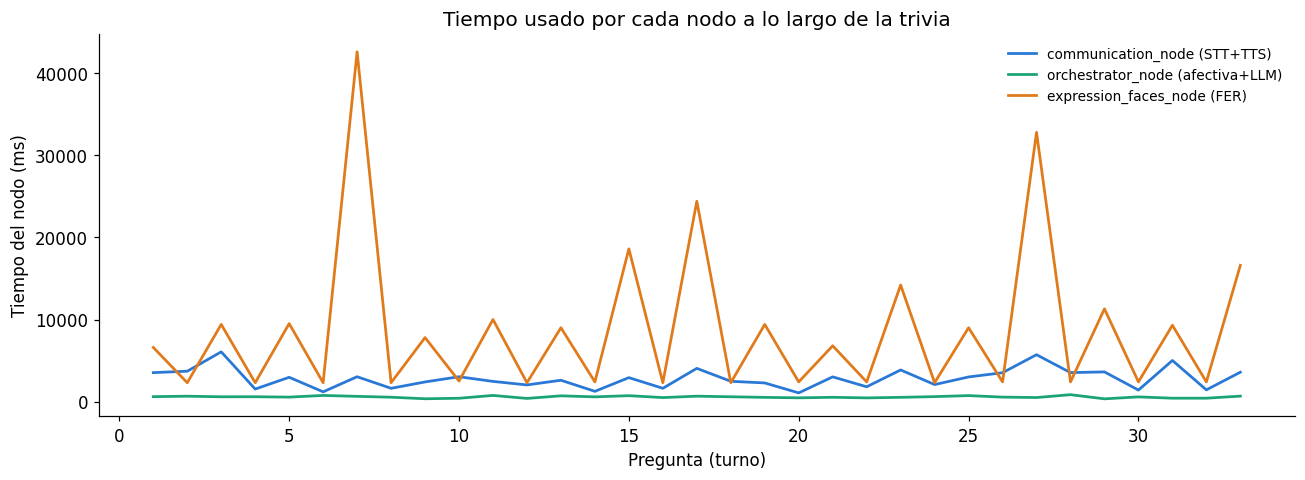

moving_control_node (carrito): no interviene en la trivia.


In [6]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["communication_node"], color=AZUL, lw=1.8, label="communication_node (STT+TTS)")
ax.plot(x, dft["orchestrator_node"], color=VERDE, lw=1.8, label="orchestrator_node (afectiva+LLM)")
ax.plot(x, dft["expression_faces_node"], color=NARANJA, lw=1.8, label="expression_faces_node (FER)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo del nodo (ms)")
ax.set_title("Tiempo usado por cada nodo a lo largo de la trivia")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("moving_control_node (carrito): no interviene en la trivia.")

## 5. Latencia de respuesta por interacción (medida en la Raspberry)

Tiempo desde que el usuario termina de hablar hasta que Romeo responde, por
cada pregunta de la trivia. Se mide en la Pi con los instantes del log
(fin de la transcripción → inicio de la respuesta del asistente), de inicio
a fin, sin depender del PC.

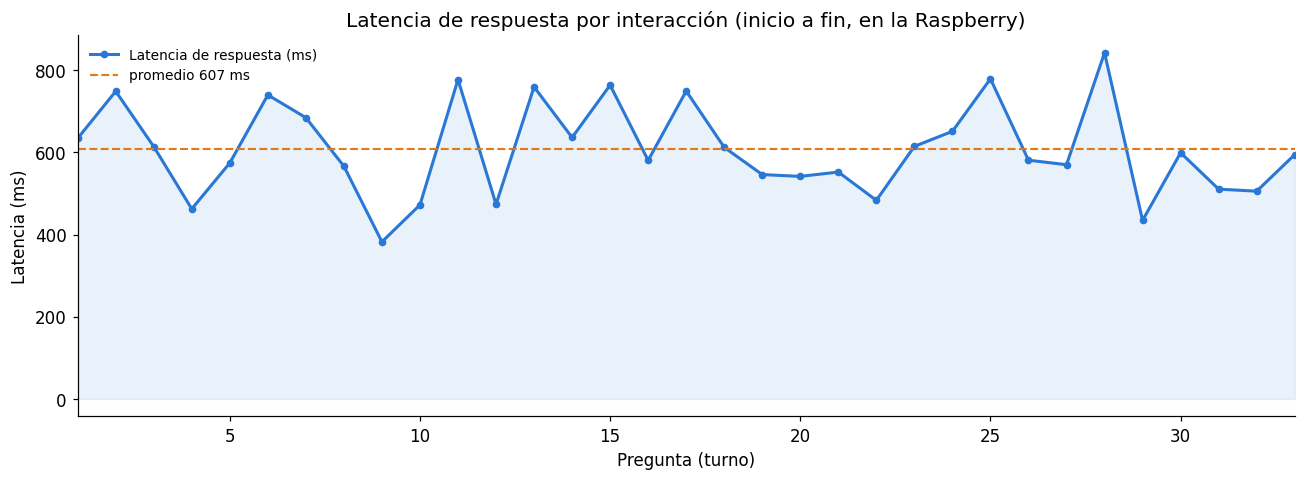

Latencia: promedio 607 ms, min 382, max 842 ms


In [7]:
import re
# latencia por interaccion: del fin de la transcripcion al inicio de la respuesta
log = open(ruta("romeo_run.log"), encoding="utf-8", errors="replace").read()
lineas = log.splitlines()
latencias = []
t_mic = None
for ln in lineas:
    m = re.search(r"\[(\d+\.\d+)\]", ln)
    if not m: continue
    ts = float(m.group(1))
    if "[mic] transcrito:" in ln:
        t_mic = ts
    elif "Asistente:" in ln and t_mic is not None and ts >= INICIO_TRIVIA:
        lat = (ts - t_mic) * 1000
        if 0 < lat < 30000:
            latencias.append(lat)
        t_mic = None
latencias = latencias[:N_PREGUNTAS]

fig, ax = plt.subplots(figsize=(12,4.5))
xx = range(1, len(latencias) + 1)
ax.plot(xx, latencias, color="#2a78d6", lw=2, marker="o", ms=4,
        label="Latencia de respuesta (ms)")
ax.axhline(np.mean(latencias), color=NARANJA, ls="--", lw=1.4,
           label=f"promedio {np.mean(latencias):.0f} ms")
ax.fill_between(xx, 0, latencias, color="#2a78d6", alpha=0.10)
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Latencia (ms)")
ax.set_xlim(1, len(latencias))
ax.set_title("Latencia de respuesta por interacción (inicio a fin, en la Raspberry)")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print(f"Latencia: promedio {np.mean(latencias):.0f} ms, min {min(latencias):.0f}, max {max(latencias):.0f} ms")

## 6. Tiempo de la capa afectiva (PULSE + ROSE + AEB)

Latencia de la capa afectiva por turno. Es puramente aritmética (fusión VAD,
empatía y mapeo), así que su costo es de pocos milisegundos: despreciable
frente al LLM o la síntesis de voz.

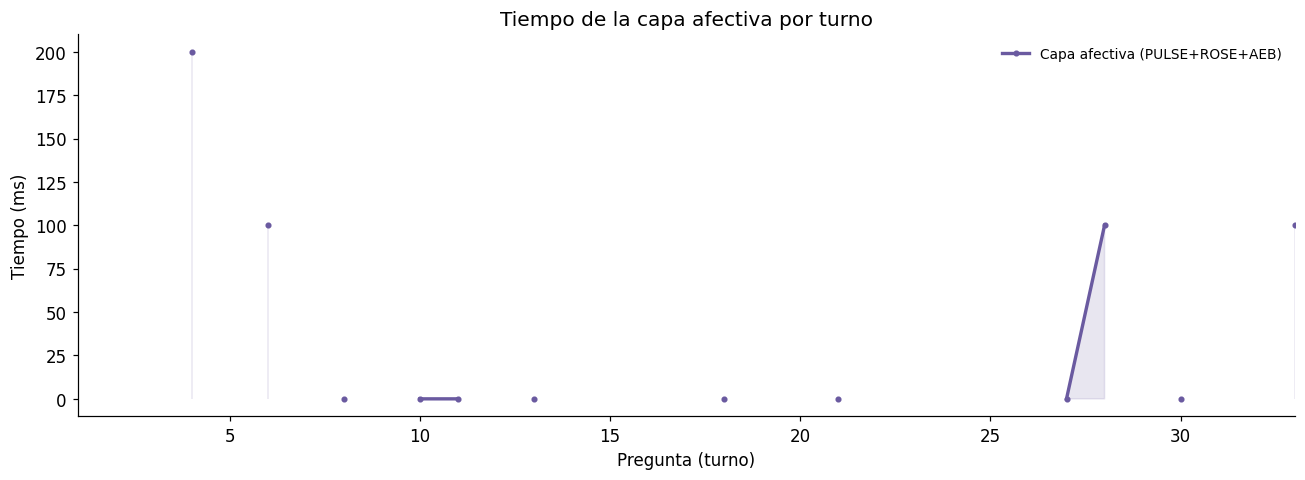

Capa afectiva: promedio 41.67 ms, máx 200.0 ms (es aritmética)


In [8]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["afectiva"], color="#6a5aa0", lw=2.2, marker="o", ms=3,
        label="Capa afectiva (PULSE+ROSE+AEB)")
ax.fill_between(x, 0, dft["afectiva"], color="#6a5aa0", alpha=0.15)
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (ms)")
ax.set_xlim(1, len(dft))
ax.set_title("Tiempo de la capa afectiva por turno")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print(f"Capa afectiva: promedio {dft['afectiva'].mean():.2f} ms, máx {dft['afectiva'].max():.1f} ms (es aritmética)")

## 7. Línea de tiempo — STT, TTS y LLM durante la trivia

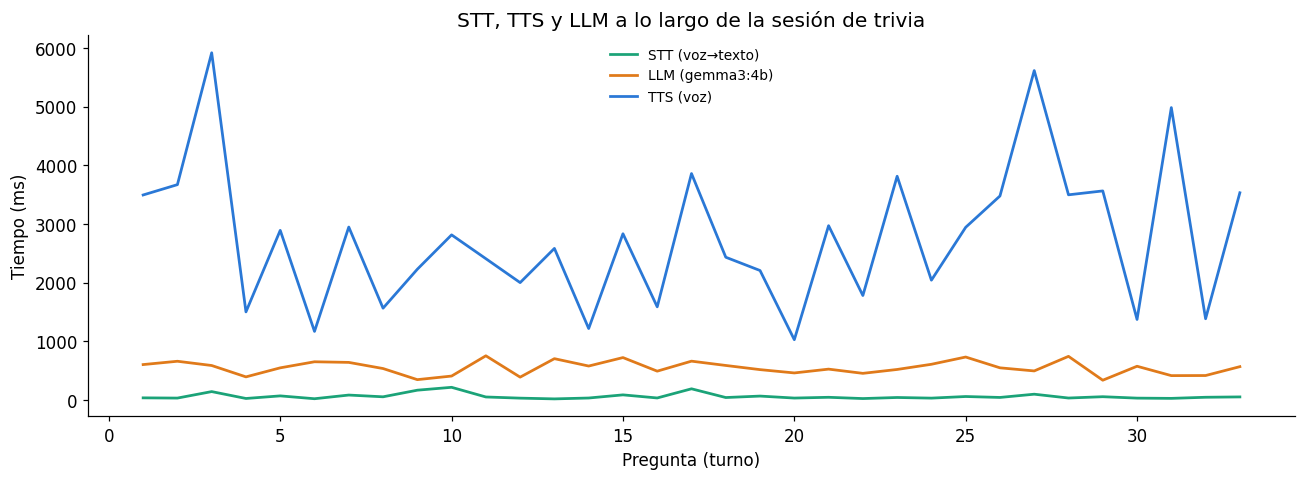

In [9]:
fig, ax = plt.subplots(figsize=(12,4.5))
x = dft["pregunta"]
ax.plot(x, dft["STT"], color=VERDE, lw=1.8, label="STT (voz→texto)")
ax.plot(x, dft["LLM"], color=NARANJA, lw=1.8, label="LLM (gemma3:4b)")
ax.plot(x, dft["TTS"], color=AZUL, lw=1.8, label="TTS (voz)")
ax.set_xlabel("Pregunta (turno)"); ax.set_ylabel("Tiempo (ms)")
ax.set_title("STT, TTS y LLM a lo largo de la sesión de trivia")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 8. Tokens del LLM

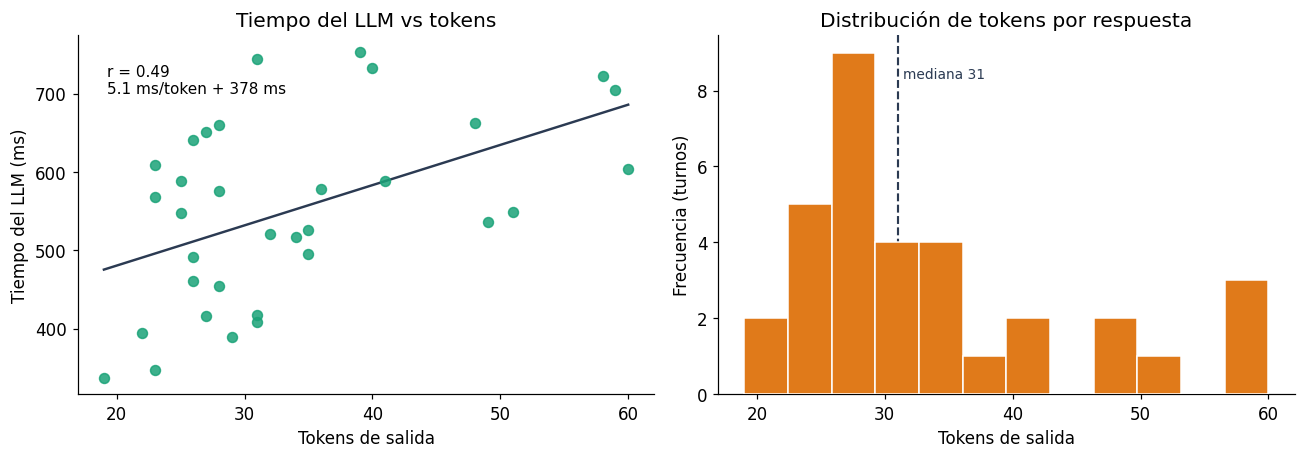

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12,4.3))
x = turnos["tokens_salida"].values; yv = turnos["t_llm_ms"].values
axs[0].scatter(x, yv, color=VERDE, s=42, alpha=0.85, zorder=3)
if len(x) > 2:
    b,a = np.polyfit(x,yv,1); xs=np.array([x.min(),x.max()])
    axs[0].plot(xs, a+b*xs, color=GRIS, lw=1.6)
    r = np.corrcoef(x,yv)[0,1]
    axs[0].text(0.05,0.92,f"r = {r:.2f}\n{b:.1f} ms/token + {a:.0f} ms",
                transform=axs[0].transAxes, va="top", fontsize=10)
axs[0].set_xlabel("Tokens de salida"); axs[0].set_ylabel("Tiempo del LLM (ms)")
axs[0].set_title("Tiempo del LLM vs tokens")
axs[1].hist(x, bins=12, color=NARANJA, zorder=3, edgecolor="white")
axs[1].axvline(np.median(x), color=GRIS, lw=1.4, ls="--")
axs[1].text(np.median(x)+0.4, axs[1].get_ylim()[1]*0.88, f"mediana {np.median(x):.0f}", fontsize=9, color=GRIS)
axs[1].set_xlabel("Tokens de salida"); axs[1].set_ylabel("Frecuencia (turnos)")
axs[1].set_title("Distribución de tokens por respuesta")
plt.tight_layout(); plt.show()

## 9. Recursos de la Raspberry Pi (de inicio a fin)

CPU total, proceso de cámara (FER), temperatura y RAM durante la sesión.

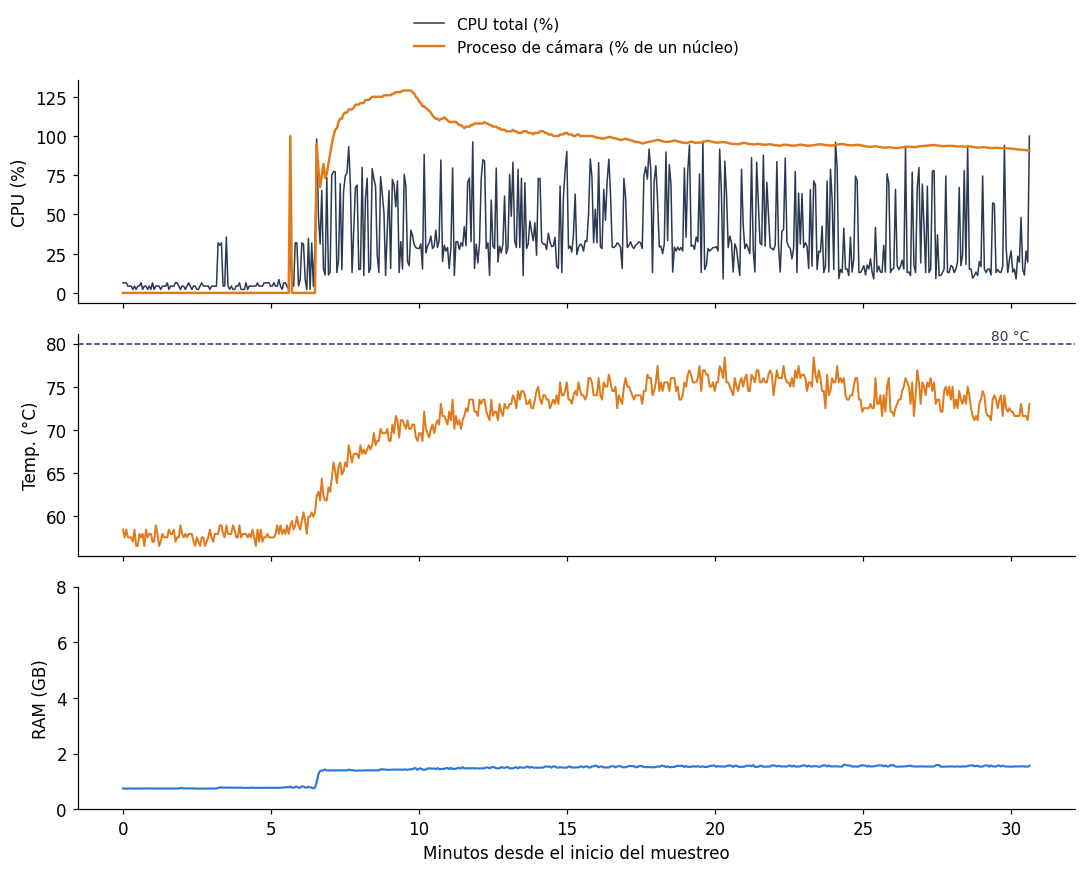

Recursos:
  CPU total:  mediana 28.3%  max 100.0%
  CPU camara: mediana 94.5%  max 129.0%
  RAM usada:  mediana 1545 MB  max 1643 MB


In [11]:
tiene_temp = (sis["temp_c"] > 0).any()
ram_gb = sis["ram_usada_mb"] / 1024
ram_total_gb = sis["ram_total_mb"].iloc[0]/1024 if "ram_total_mb" in sis.columns else 8

fig, axs = plt.subplots(3, 1, figsize=(10,8), sharex=True)
# (1) CPU total + camara
axs[0].plot(sis["min"], sis["cpu_total_pct"], color=GRIS, lw=1, label="CPU total (%)")
axs[0].plot(sis["min"], sis["cpu_camara_pct"], color=NARANJA, lw=1.6, label="Proceso de cámara (% de un núcleo)")
axs[0].set_ylabel("CPU (%)")
axs[0].legend(loc="upper center", bbox_to_anchor=(0.5,1.35), ncol=1, frameon=False, fontsize=10)
# (2) Temperatura
if tiene_temp:
    axs[1].plot(sis["min"], sis["temp_c"], color=NARANJA, lw=1.3)
    axs[1].axhline(80, color=GRIS, ls="--", lw=1)
    axs[1].text(sis["min"].max(), 80.4, "80 °C", ha="right", fontsize=9, color=GRIS)
    axs[1].set_ylabel("Temp. (°C)")
else:
    axs[1].text(0.5,0.5,"Temperatura no capturada en esta corrida\n(bug del recolector ya corregido; lectura directa 73.5 °C, pico ~80 °C)",
                transform=axs[1].transAxes, ha="center", va="center", fontsize=10, color=ROJO)
    axs[1].set_ylabel("Temp. (°C)"); axs[1].set_yticks([])
# (3) RAM
axs[2].plot(sis["min"], ram_gb, color=AZUL, lw=1.4)
axs[2].set_ylabel("RAM (GB)"); axs[2].set_ylim(0, ram_total_gb)
axs[2].set_xlabel("Minutos desde el inicio del muestreo")
plt.tight_layout(); plt.show()

print("Recursos:")
print(f"  CPU total:  mediana {sis['cpu_total_pct'].median():.1f}%  max {sis['cpu_total_pct'].max():.1f}%")
print(f"  CPU camara: mediana {sis['cpu_camara_pct'].median():.1f}%  max {sis['cpu_camara_pct'].max():.1f}%")
print(f"  RAM usada:  mediana {sis['ram_usada_mb'].median():.0f} MB  max {sis['ram_usada_mb'].max():.0f} MB")

## 10. Tabla resumen (trivia)

In [12]:
def prom1(s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return round(s.mean(),1) if len(s) else np.nan

tabla = []
for nombre, serie, unidad, nodo in [
    ("STT (voz→texto)", mod["t_stt_ms"], "ms", "communication / PC"),
    ("SER (emoción voz)", mod["t_ser_ms"], "ms", "communication / PC"),
    ("TER (emoción texto)", mod["t_ter_ms"], "ms", "communication / PC"),
    ("Afectiva PULSE+ROSE+AEB", turnos["afectiva_ms"], "ms", "orchestrator / Pi"),
    ("Respuesta LLM", turnos["t_llm_ms"], "ms", "orchestrator / Pi→PC"),
    ("Síntesis TTS", tts["t_tts_ms"], "ms", "communication / PC"),
    ("Tokens de salida", turnos["tokens_salida"], "tokens", "orchestrator"),
    ("CPU total Pi", sis["cpu_total_pct"], "%", "Raspberry"),
    ("CPU cámara/FER", sis["cpu_camara_pct"], "%", "expression / IMX500"),
    ("RAM usada Pi", sis["ram_usada_mb"], "MB", "Raspberry"),
]:
    tabla.append([nombre, prom1(serie), unidad, nodo])
df = pd.DataFrame(tabla, columns=["Indicador","Promedio","Unidad","Nodo / máquina"])
print("Coincidencia Rocha vs IA: 27/30 = 90%\n")
df

Coincidencia Rocha vs IA: 27/30 = 90%



,Indicador,Promedio,Unidad,Nodo / máquina
0,STT (voz→texto),74.6,ms,communication / PC
1,SER (emoción voz),206.4,ms,communication / PC
2,TER (emoción texto),19.4,ms,communication / PC
3,Afectiva PULSE+ROSE+AEB,41.7,ms,orchestrator / Pi
4,Respuesta LLM,551.4,ms,orchestrator / Pi→PC
5,Síntesis TTS,2541.6,ms,communication / PC
6,Tokens de salida,33.8,tokens,orchestrator
7,CPU total Pi,32.0,%,Raspberry
8,CPU cámara/FER,78.7,%,expression / IMX500
9,RAM usada Pi,1378.3,MB,Raspberry
